# Milestone 3: Low-Rank Prediction with the SVD
MATH 344L — Project 2: A Movie Recommendation System

In this notebook I use the SVD to find patterns in the user–movie rating matrix and compare several low-rank models against the bias baseline. Model settings (the rank k) are chosen on a **validation** set; the **test** set is used only once at the end.

## Part A: Load project functions and data

In [1]:
import os
import subprocess
import sys

USER = "CSCEJJQ"
REPO = "344Lab"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline, baseline_matrix, rank_k, iterative_svd_predict

Already up to date.


This cell gets my GitHub repo (it clones it, or pulls if it's already there) and tells Python to look in the `src/` folder. That way I can import my own functions from `evaluate.py` and `models.py`.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 64000 validation: 16000 test: 20000


This downloads the MovieLens 100k ratings (just temporarily, I don't put it on GitHub) and splits them twice. The first split sets aside the test ratings. The second split divides what's left into a fit set to build the models and a validation set to pick the settings.

## Part B: Set up a fair validation comparison

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

`R_fit` is the user-by-movie matrix made only from the fit ratings, with `NaN` where a user hasn't rated a movie. `val_u` and `val_i` tell me which row and column each validation rating belongs to. `score_at` grabs those spots from a prediction matrix, limits them to between 1 and 5, and gives the RMSE. None of the validation ratings are used to build the models.

## Part C: Baseline prediction matrix

In [4]:
B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9529


The baseline predicts the overall average rating plus an adjustment for the user and an adjustment for the movie. NumPy broadcasting turns the column of user adjustments and the row of movie adjustments into a prediction for every pair. Every model below has to beat this number.

## Part D: Rank-k helper

In [5]:
# rank_k is imported from src/models.py:
#   def rank_k(U, s, Vt, k):
#       return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
print(rank_k.__doc__)

Build a rank-k matrix from an already computed SVD.


`rank_k` keeps only the first k singular values and their vectors, which gives the best rank-k version of the matrix. I compute the SVD once and then just slice it for each k, which is much faster than redoing it.

## Part E: Model 1 — fill gaps with movie averages

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

The SVD needs a matrix with no gaps, so for Model 1 I fill each empty spot with that movie's average rating from the fit data (or the overall average if the movie has no ratings there). The ratings I know stay the same. Then I take the SVD of this filled matrix `F`.

## Part F: Model 2 — SVD of what the baseline misses

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

The baseline already accounts for the overall level, generous users, and popular movies. For Model 2 I take what's left over, `R - B`, at the known ratings and put 0 at the gaps, since there is no deviation to look at there. The SVD then looks for patterns in those leftovers. To predict, I add the low-rank part back to the baseline.

## Part G: Choose the rank using validation RMSE

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []
for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, "validation RMSE:", min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9933341984914313
Best Model 2 k: 5 validation RMSE: 0.9403733897299112


For each rank, I score both models on the validation set. `np.argmin` finds the smallest error and I use that position to look up the best k in `ks`. For Model 2 I add `B_fit` back at the end, because its low-rank matrix is made of deviations and not star ratings.

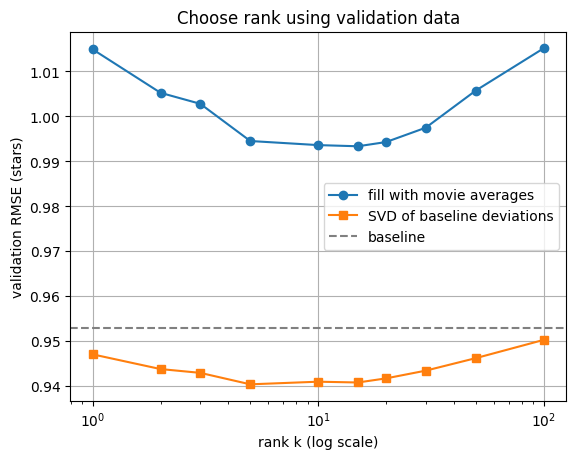

In [9]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",
            label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

The dashed gray line is the baseline. Lower is better, so a model above the line isn't an improvement. The best validation rank is only the setting I picked. I still need the test set, which I haven't used, for the final check. (I copied the saved PNG into `figures/`.)

## Part H: Model 3 — iteratively improve the missing-value guesses

In [10]:
# iterative_svd_predict is imported from src/models.py:
#   known entries keep their true deviation R - B; gaps are repeatedly
#   replaced by the current rank-k estimate, then the SVD is recomputed.
ks_iter = [2, 5, 10, 20]
val_err3 = []
for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Iterative validation RMSEs:", {k: round(float(e), 4) for k, e in zip(ks_iter, val_err3)})
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Iterative validation RMSEs: {2: 0.9386, 5: 0.943, 10: 0.9617, 20: 0.9902}
Best iterative rank: 2
Best validation RMSE: 0.9386494619187082


In Model 2 all the gaps started at 0. In Model 3 I keep replacing the gaps with the current rank-k guess, keep the known deviations fixed, and take the SVD again. Each round needs a new SVD, so I only try a few ranks. After that I compare all the models.

In [11]:
print(f"baseline            : {baseline_val_rmse:.4f}")
print(f"Model 1 (k={best_k1:>3})    : {min(val_err1):.4f}")
print(f"Model 2 (k={best_k2:>3})    : {min(val_err2):.4f}")
print(f"Model 3 (k={best_k3:>3})    : {min(val_err3):.4f}")

baseline            : 0.9529
Model 1 (k= 15)    : 0.9933
Model 2 (k=  5)    : 0.9404
Model 3 (k=  2)    : 0.9386


This lists the best validation RMSE for each model next to the baseline. I pick the model and rank for the final test based only on these validation numbers.

## Part I: Refit on all of train and evaluate on the test set once

In [12]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9447
Chosen model test RMSE: 0.9294


Now I use the model and rank I picked on validation, refit it on all of `train` (fit plus validation), and score it on the test set one time. I don't change anything after seeing this number, because then the test set would just be another validation set.

## Part J: A few recommendations

In [13]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1")
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(title, "predicted rating:", round(predicted_scores[col], 2))

Aiqing wansui (1994) predicted rating: 5.0
Marlene Dietrich: Shadow and Light (1996)  predicted rating: 5.0
Someone Else's America (1995) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Entertaining Angels: The Dorothy Day Story (1996) predicted rating: 5.0


The chosen prediction matrix gives a score for every user and movie pair. For user 1, this prints the five movies with the highest predicted rating out of the ones they haven't rated in the training data. The columns start at 0 but MovieLens IDs start at 1, so I add 1 to find the title.

---
# Practice Exercises

## Exercise 1: Does filling matter?

In [14]:
def model1_val_rmse(fill_matrix, ranks):
    U, s, Vt = np.linalg.svd(fill_matrix, full_matrices=False)
    return [score_at(rank_k(U, s, Vt, k), val_u, val_i, val_truth) for k in ranks]

ranks_ex1 = [1, 2, 5, 10, 20]
fills = {
    "movie average": np.where(known_fit, R_fit, item_mean[None, :]),
    "overall average": np.where(known_fit, R_fit, mu_fit),
    "3 stars": np.where(known_fit, R_fit, 3.0),
    "0 stars": np.where(known_fit, R_fit, 0.0),
}
ex1 = pd.DataFrame({name: model1_val_rmse(M, ranks_ex1) for name, M in fills.items()},
                   index=[f"k={k}" for k in ranks_ex1])
print(ex1.round(4))

      movie average  overall average  3 stars  0 stars
k=1          1.0149           1.0915   1.1736   2.6369
k=2          1.0052           1.0795   1.1397   2.6073
k=5          0.9945           1.0661   1.1143   2.5498
k=10         0.9936           1.0555   1.1079   2.5131
k=20         0.9943           1.0576   1.1158   2.5352


Filling with the movie average worked best at every rank I tried. At k=10 it got a validation RMSE of about 0.994, compared with about 1.056 for the overall average, 1.108 for 3 stars, and about 2.5 for 0 stars.

I think this is because the SVD treats the filled-in numbers like real ratings. Most of the matrix is empty, so whatever I fill in with ends up being most of what the SVD sees. A movie's average is the closest guess to what someone would really rate it, so it adds the least fake pattern. 3 stars and the overall average treat every movie as the same. Filling with 0 stars is a bad idea because nobody can give a rating of 0 (the scale is 1 to 5). The SVD would just learn "empty spot = 0" and drag the predictions way too low.

## Exercise 2: The full-rank check

In [15]:
k_full = min(X_fit.shape)
X_full = rank_k(U2, s2, Vt2, k_full)
print("max |X_full - X_fit| :", np.abs(X_full - X_fit).max())

P_full = X_full + B_fit
gap_rows, gap_cols = np.where(~known_fit)
print("max |P_full - B_fit| at gaps:", np.abs(P_full - B_fit)[gap_rows, gap_cols].max())
print("full-rank validation RMSE:", round(score_at(P_full, val_u, val_i, val_truth), 4))
print("baseline validation RMSE :", round(baseline_val_rmse, 4))

max |X_full - X_fit| : 2.73468903322725e-14
max |P_full - B_fit| at gaps: 2.7533531010703882e-14
full-rank validation RMSE: 0.9529
baseline validation RMSE : 0.9529


At full rank the SVD can rebuild its input matrix exactly. My check shows the difference is about 1e-14, which is basically zero. The input matrix `X_fit` has 0 in every gap, so the rebuilt matrix also has 0 in every gap. Adding `B_fit` back then gives just the baseline at those spots. The full-rank validation RMSE (0.9529) is the same as the baseline's, which matches this.

That doesn't mean the model learned anything. At full rank it just copies what it was given and keeps the zeros I made up. It never found a pattern across users or movies. The useful patterns only show up at a low rank, where the SVD has to throw information away and keep only the biggest shared trends.

## Exercise 3: Study iteration

In [16]:
iters = [1, 2, 5, 10]
ex3 = [score_at(iterative_svd_predict(R_fit, 5, n_iter=n), val_u, val_i, val_truth)
       for n in iters]
for n, e in zip(iters, ex3):
    print(f"rounds = {n:>2}: validation RMSE = {e:.4f}")
print(f"(Model 2, k=5, equivalent to 1 round: {val_err2[ks.index(5)]:.4f})")

rounds =  1: validation RMSE = 0.9404
rounds =  2: validation RMSE = 0.9363
rounds =  5: validation RMSE = 0.9365
rounds = 10: validation RMSE = 0.9430
(Model 2, k=5, equivalent to 1 round: 0.9404)


For Model 3 at rank 5, the validation RMSE was 0.9404 after 1 round, 0.9363 after 2, 0.9365 after 5, and 0.9430 after 10. So more iteration helped at first, but it did not keep helping. It got a bit worse after about 2 to 5 rounds.

My guess is that each round makes the filled-in guesses fit the training data more closely, so the model starts to overfit. That means the number of rounds is another setting I should pick with the validation set. Here 2 to 5 rounds looks better than 10.

## Exercise 4: Check for overfitting

In [17]:
print("Validation RMSE by rank:")
print(pd.DataFrame({"k": ks, "Model 1": np.round(val_err1, 4), "Model 2": np.round(val_err2, 4)}).to_string(index=False))
print("\nIterative:", {k: round(float(e), 4) for k, e in zip(ks_iter, val_err3)})
print("\nChosen model:", chosen_model)
print("Validation RMSE of chosen:", round(min(val_err1 + val_err2 + val_err3), 4))
print("Single test RMSE of chosen:", round(test_rmse, 4))

Validation RMSE by rank:
  k  Model 1  Model 2
  1   1.0149   0.9470
  2   1.0052   0.9438
  3   1.0028   0.9429
  5   0.9945   0.9404
 10   0.9936   0.9410
 15   0.9933   0.9408
 20   0.9943   0.9417
 30   0.9975   0.9434
 50   1.0057   0.9462
100   1.0151   0.9503

Iterative: {2: 0.9386, 5: 0.943, 10: 0.9617, 20: 0.9902}

Chosen model: iterative SVD
Validation RMSE of chosen: 0.9386
Single test RMSE of chosen: 0.9294


As the rank goes up, the validation RMSE first drops, hits its lowest point at a small rank, and then climbs again. Model 2 is lowest at k=5 (0.9404) and gets to 0.9503 by k=100. Model 1 goes from 0.9933 at its best up to 1.0151 at k=100. A larger rank can fit more of the noise in the fitting data, which is overfitting.

My chosen model (iterative SVD with k=2) had a validation RMSE of 0.9386 and a test RMSE of 0.9294. The two are close, so the choice seems to hold up on new data.

The rank has to be picked before looking at the test results. If I picked it using the test set, the test set would be helping me tune the model, so the final number would look better than it really is and would not be an honest check.

## Exercise 5: Cold-start limitation

If a new user has no ratings, the model has nothing to say about their taste. Their user effect is 0 and there is nothing for the SVD to use. So it can only predict the overall average plus each movie's effect, which means every new user gets the same list of generally popular movies.

Some things that would help are: asking the user to rate a few movies when they sign up, using info about them (MovieLens includes age, gender and occupation), using movie info like genre, or using other behavior such as what they watch or click on.

## Exercise 6: Explain the result

The baseline (overall average plus user effect plus movie effect) has a test RMSE of 0.9447, so its predictions are off by about 0.94 stars on average. My chosen model (iterative SVD, rank 2) got 0.9294, which is better by about 0.015 stars. That is a real improvement but a small one. Most of what we can predict comes from knowing which users rate high and which movies are popular, and the low-rank part only adds a little more.

The example recommendations for user 1 are all predicted at exactly 5.0 and are obscure movies, like "Aiqing wansui" and "Someone Else's America." This does not mean user 1 will love them. I think those movies have very few ratings, so their estimates are noisy and happened to come out extreme. RMSE tells us how accurate the predictions are on average across many hidden ratings, but it does not tell us whether a top-5 list is good. Handling movies with few ratings more carefully would probably give better recommendations.